# Biweekly Report 2

## Candido Seneriches IV

### PRELU and HE Initialization
In this part of my report, I wanted to explore how different different activation functions and weight initialization methods can affect the performance of convolutional neural networks (CNNs). Specifically, I will be looking at the methods prescribed the 2015 paper: **Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification** by Kaiming He et. al, which means I will be implementing ReLU, Leaky ReLU, and PReLU, alongside Xavier and He Initialization, and see how these methods influence the training process.

For this report, I will use the **CIFAR-10** dataset (Provided on Kaggle [Here](https://www.kaggle.com/datasets/pankrzysiu/cifar10-python/data)) to train the CNNs under different configurations and compare their accuracy, convergence and overall behavior. I will also use this opportunity to explore the dataset alongside this experiment. With that being said, let's get started by loading the data. 

In [1]:
# Verify a GPU is available
import torch
import os

print("Working directory:", os.getcwd())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Working directory: /kaggle/working
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU count: 2
GPU: Tesla T4


In [2]:
import os

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

seed = 42
batch_size = 128

DATA_DIR = "/kaggle/input/datasets/pankrzysiu/cifar10-python"

torch.manual_seed(seed)



In [3]:
# Convert the immage into a tensor and standarize the RGB channels
transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize(
    mean=(0.4914, 0.4822, 0.4465),
    std=(0.2470, 0.2435, 0.2616)
  )
])

# Load in CIFAR-10
full_train_dataset = datasets.CIFAR10(
  root=DATA_DIR,
  train=True,
  download=False,
  transform=transform
)

test_dataset = datasets.CIFAR10(
  root=DATA_DIR,
  train=False,
  download=False,
  transform=transform
)

print("Training samples:", len(full_train_dataset))
print("Testing samples:", len(test_dataset))
print("Classes:", full_train_dataset.classes)

Training samples: 50000
Testing samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [4]:
# Splitting the data into training, validation, and test data
train_dataset, val_dataset = random_split(
  full_train_dataset,
  [40000, 10000],
  generator=torch.Generator().manual_seed(seed)
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 40000
Validation samples: 10000
Testing samples: 10000


In [5]:
train_loader = DataLoader(
  train_dataset,
  batch_size=batch_size,
  shuffle=True,
  num_workers=2
)

val_loader = DataLoader(
  val_dataset,
  batch_size=batch_size,
  shuffle=False,
  num_workers=2
)

test_loader = DataLoader(
  test_dataset,
  batch_size=batch_size,
  shuffle=False,
  num_workers=2
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of testing batches:", len(test_loader))

Image batch shape: torch.Size([128, 3, 32, 32])
Label batch shape: torch.Size([128])
Image data type: torch.float32
Number of training batches: 313
Number of validation batches: 79
Number of testing batches: 79


Before going on, I should introduce the CIFAR-10 dataset for those who don't know what it is and how we are going to use it. This dataset contains 60,000 colored images divided into 10 different classes, including airplanes, automobiles, birds, cats, and dogs. Each image has a resolution of $32 \times 32$ pixels, which makes it a relatively small but useful dataset.

Since the main goal of the notebook is to investigate how activation functions like ReLU, leaky ReLU and PReLU interact with different weight initialization methods, CIFAR-10 provides a good starting point without needing a large dataset. By training CNNs on the same images under different configurations, I can compare their training behavior, convergence, and classification accuracy to better understand how these mathematical techniques affect neural network performance.

With this in mind, let's explore the dataset itself to see what we're diving into.

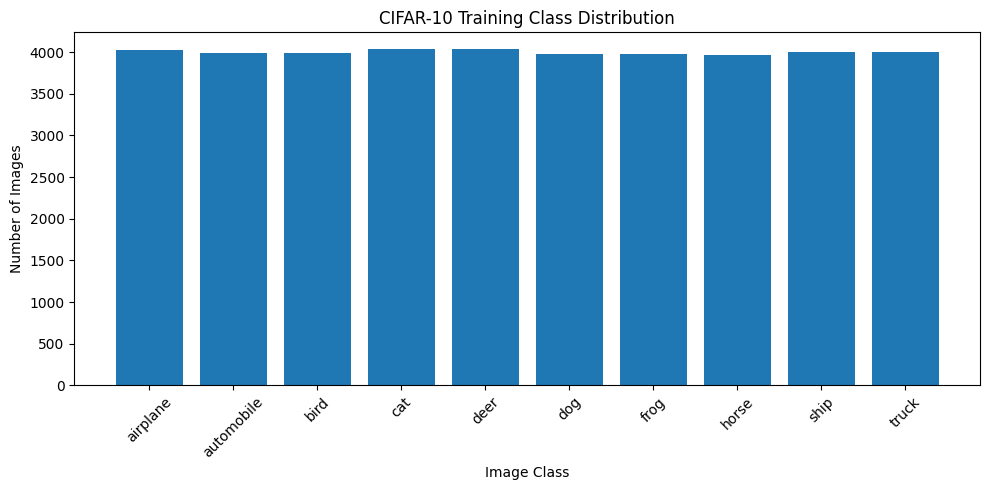

In [6]:
import matplotlib.pyplot as plt
import numpy as np

class_names = full_train_dataset.classes

train_labels = np.array(full_train_dataset.targets)[train_dataset.indices]

class_counts = np.bincount(
  train_labels,
  minlength=len(class_names)
)

plt.figure(figsize=(10, 5))
plt.bar(class_names, class_counts)

plt.title("CIFAR-10 Training Class Distribution")
plt.xlabel("Image Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Here, the graph shows the distribution of images across the 10 classes in the dataset, with each class containing around 4,000 images with only slight differences between them. Overall, the dataset appears to be well-balanced with no class being overrepresented. This will be good for my investigation as since I'll be comparing different activation functions and weight initialization methods, I will want to have the influence of class imbalanced minimized on the results.

Next, let's see some of the CIFAR-10 images to get a sense of what we're doing

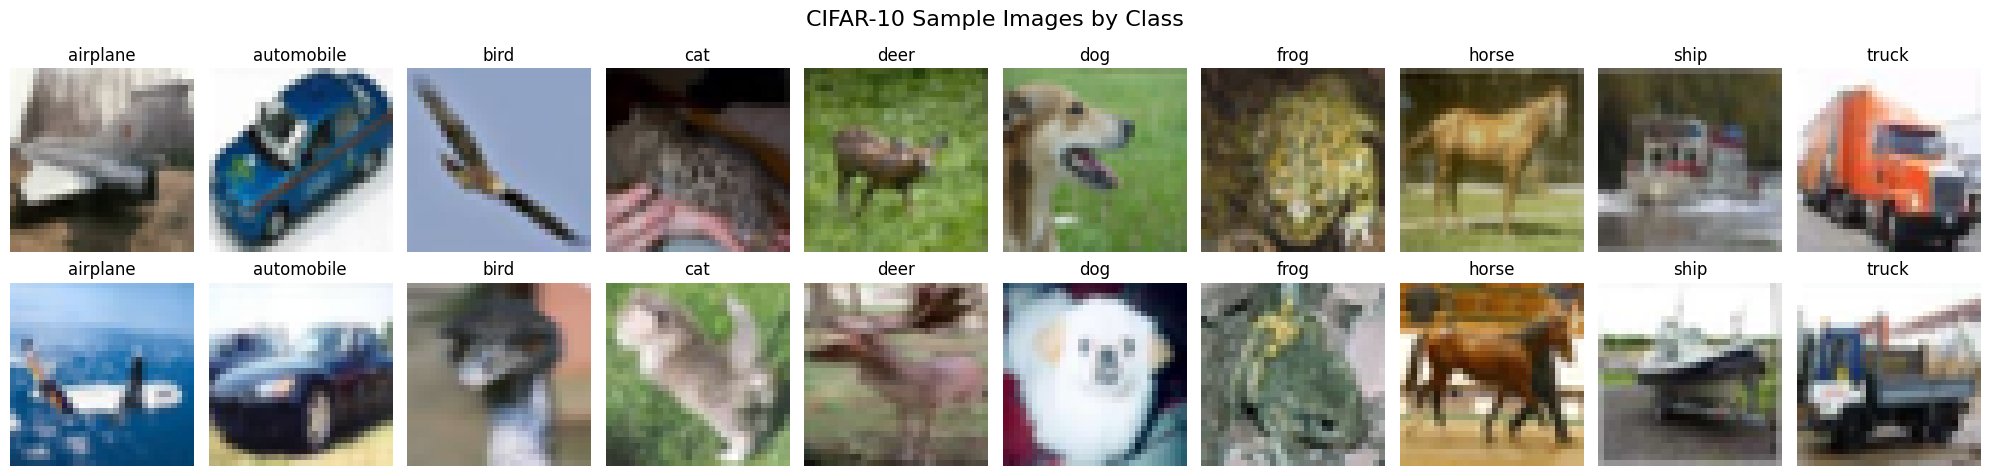

In [7]:
fig, axes = plt.subplots(2, 10, figsize=(20, 5))

rng = np.random.default_rng(seed)
labels = np.array(full_train_dataset.targets)

for class_idx, class_name in enumerate(class_names):
  class_indices = np.where(labels == class_idx)[0]
  selected_indices = rng.choice(class_indices, size=2, replace=False)

  for j, idx in enumerate(selected_indices):
    image, label = full_train_dataset[int(idx)]

    # Reverse normalization for visualization
    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

    image = image * std + mean
    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image, 0, 1)

    axes[j, class_idx].imshow(image)
    axes[j, class_idx].set_title(class_name)
    axes[j, class_idx].axis("off")

plt.suptitle("CIFAR-10 Sample Images by Class", fontsize=16)
plt.tight_layout()
plt.show()

Here above, we see two randomly selected images from each of the ten classes from CIFAR-10. With the $32 \times 32$ resolution, certain objects within the images themselves are difficult to distinguish, and the images themselves have differing appearances, backgrounds, and orientation. These obscured details are important for the investigation, as the CNN needs to learn useful visual features to correctly classify these images, and with how disfigured they are, I can investigate how the choices in activation functions and weight initialization methods can affect the network's ability to learn from the dataset.

The final aspect of the dataset I want to cover is the RGB pixel intensity as shown below.

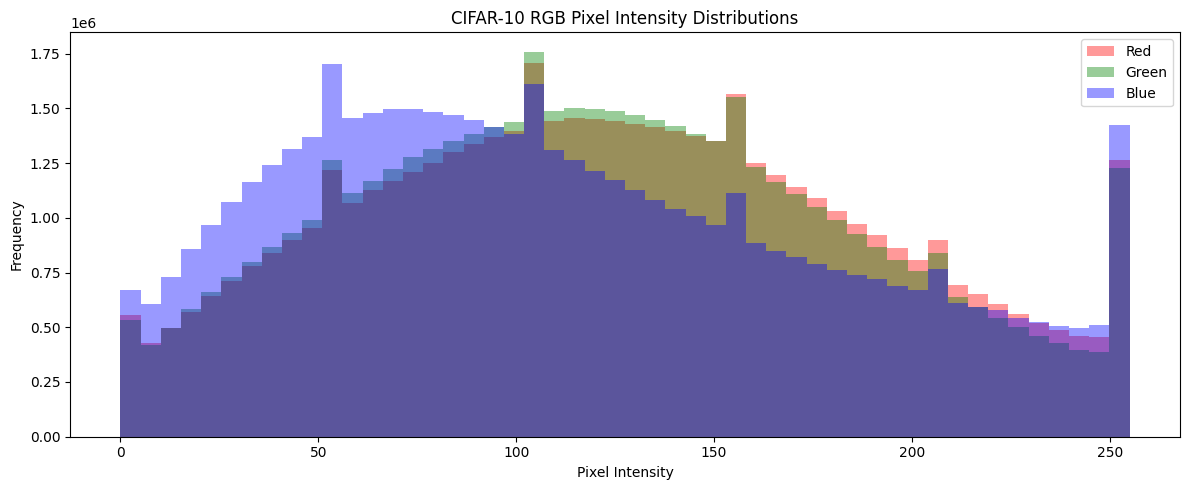

In [8]:
# Extract original pixel values
images = full_train_dataset.data

# Flatten each color channel
red = images[:, :, :, 0].flatten()
green = images[:, :, :, 1].flatten()
blue = images[:, :, :, 2].flatten()

# Plot RGB distributions
plt.figure(figsize=(12, 5))

plt.hist(red, bins=50, alpha=0.4, color="red", label="Red")
plt.hist(green, bins=50, alpha=0.4, color="green", label="Green")
plt.hist(blue, bins=50, alpha=0.4, color="blue", label="Blue")

plt.title("CIFAR-10 RGB Pixel Intensity Distributions")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

Breaking it down, the histogram shows a distribution of the RGB pixel intensities across the dataset, with each color channel having values ranging from 0 to 255, and with the vertical axis representing how frequently certain intensities appear. From the graph, we can see that the three channels overlap considerably, although there's some differences in where the intensities are concentration.

One interesting observation is that the blue channel has relatively more values in some of the lower-intensity ranges, while the red and green channels have higher frequencies across parts of the middle-intensity range. These differences help explain why we normalize each color channel separetly before training the CNN. By doing so, we can keep the input values on more comparable scales, which should help make training more stable.

#### CNNs, Types of ReLUs, and Weight Initialization
Now that we established what the CIFAR-10 datset is, now let's focus on meat of the report, **understanding how activation functions and weight initialization affect the training of convolutional neural networks (CNNs).***

Starting off, our CNN will process the images through several $3 \times 3$ convolutional layers, meaning that each filter examines a $3 \times 3$ region of the input at a time. Since CIFAR-10 images contain three RGB channels, each filter in the first convolutional layer has $3 \times 3 \times 3 = 27$ learnable weights excluding the bias. Mathematically it looks like this

$$
z_{i, j, k} = b_k + \sum_{c = 1}^{C} \sum_{u = 0}^{2} \sum_{v = 0}^{2} W_{u, v, c, k}x_{i + u, j + v, c}
$$

For:
- $x$ represents the input feature maps
- $W$ represents the learnable convolutional filters
- $b_k$ is a bias
- $K$ is the filter size
- $z$ is the resulting output before applying an activation function.

This operation allows the CNN to learn features such as edges, textures, and even complex visual patters. However convolution itself is a linear operation with respect to its input. To learn more complicated relationships, nonlinear activation functions are needed.

Enter ReLUs, defined as

$$
\boxed{f(x) = \max(0, x)}
$$

Or equivalently

$$
f(x) =
\begin{cases}
  x, \quad x > 0 \\
  0, \quad x < 0
\end{cases}
$$

Taking the derivative is

$$
f'(x) =
\begin{cases}
  1, \quad x > 0 \\
  0, \quad x < 0
\end{cases}
$$

Interestingly when $x < 0$, the derivative becomes zero, meaning the gradient through that activation is also zero. This contributes to a problem called the **dying ReLU problem**, in which certain neurons can become inactive and stop learning. To solve this issue, there's two methods that can be implemented, one is called Leaky ReLU which modifies the $x < 0$ portion

$$
f(x) =
\begin{cases}
  x, \quad x > 0 \\
  ax, \quad x < 0
\end{cases}
$$

For $a$ is a small, fixed positive constant (i.e $0.01$). With this the derivative becomes

$$
f'(x) =
\begin{cases}
  1, \quad x > 0 \\
  a, \quad x < 0
\end{cases}
$$

Meaning negative inputs can still propagate nonzero gradients. Another method is Parametric ReLU (PReLU) which takes the Leaky ReLU a step further by allowing the neural network to learn $a$, making it a trainable parameter. During backpropagation, we can calculate

$$
\frac{\partial f}{\partial a} =
\begin{cases}
  0, \quad x > 0 \\
  x, \quad x < 0
\end{cases}
$$

Meaning the network can adjust the negative slope via gradient-based optimization. Therefore the first experiment will investigate whether learning the parameter improves training compared with using a fixed activation function.

Another aspect to CNNs is how the weights are initialized. Before training can begin, the network's weights must be assigned initial values with these values mattering in the sense that signals repeatedly pass through weighted operations and activation functions. If the magnitudes grow quick, activations and or gradients will explode. If they shrink to quickly on the flip side, activations or gradients will vanish.

In this case, there's two ways of initializing them; the first is **Xavier initialization**, which is designed to help maintain reasonable variance across layers, particularly for approximately linear or symmetric activations. A common version of this initialization uses

$$
\boxed{\operatorname{Var}(W) = \frac{2}{n_{\text{in}} + n_{\text{out}}}}
$$

For
- $n_{\text{in}}$ is the number of input connections
- $n_{\text{out}}$ is the number of output connections

The other type is called **He initialization**, and it was developed with rectifier-based activation functions in mind. For ReLU, its standard variance is

$$
\boxed{\operatorname{Var}(W) = \frac{2}{n_{\text{in}}}}
$$

Since ReLU suppresses approximately half of the input values. He initialization compensates for this effect to help preserve activation variance across layers.

For a rectifier with negative slope $a$, a generalized form is

$$
\boxed{\operatorname{Var}(W) = \frac{2}{(1 + a^2)n_{\text{in}}}}
$$

Putting these concepts together, this report will investigate two main questions, the first experiment investigates the effect that activation functions have on CNN training, and I'll answer this by comparing ReLU, Leaky ReLU, and PreLU while keeping the architecture, initialization strategy, and other training settings constant. The second investigates weight initialization by comparing Xavier and He initialization while holding the activation function constant. For both experiments, the training loss, validation accuracy, convergence, activation variance, gradient behavior, and learned PReLU slopes will be examined.

With all of that being said, let's start building the CNN architecture

In [9]:
import torch.nn as nn

class CIFAR10CNN(nn.Module):
  def __init__(self, activation="relu"):
    super().__init__()

    def make_activation(channels):
      if activation == "relu":
        return nn.ReLU()

      elif activation == "leaky_relu":
        return nn.LeakyReLU(negative_slope=0.01)

      elif activation == "prelu":
        return nn.PReLU(num_parameters=channels, init=0.25)

      else:
        raise ValueError(f"Unknown activation function: {activation}")

    self.features = nn.Sequential(
      nn.Conv2d(3, 32, kernel_size=3, padding=1),
      make_activation(32),

      nn.Conv2d(32, 32, kernel_size=3, padding=1),
      make_activation(32),

      nn.MaxPool2d(kernel_size=2),

      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      make_activation(64),

      nn.Conv2d(64, 64, kernel_size=3, padding=1),
      make_activation(64),

      nn.MaxPool2d(kernel_size=2)
    )

    self.classifier = nn.Sequential(
      nn.AdaptiveAvgPool2d((1, 1)),
      nn.Flatten(),
      nn.Linear(64, 10)
    )

  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)

    return x



Here, the CNN that will be used for this experiment consists of four convolutional layers, with each one using $3 \times 3$ kernels with either 32 or 64 filters. The network also includes max pooling to reduce the spatial dimensions of the images, followed by global average pooling and a fully connected layer that outputs predictions for CIFAR-10's classes.

The architecture will remain the same throughout the differing experiments, allowing us to compare how different activation functions and weight initialization methods affect the network's training performance. Speaking of weight initialization, let's go ahead and implement it.

In [10]:
import torch.nn.init as init

def initialize_weights(model, method="he"):
  if method not in ("he", "xavier"):
    raise ValueError(f"Unknown initialization method: {method}")

  for module in model.modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
      if method == "he":
        init.kaiming_normal_(
          module.weight,
          mode="fan_in",
          nonlinearity="relu"
        )

      elif method == "xavier":
        init.xavier_normal_(module.weight)

      if module.bias is not None:
        init.zeros_(module.bias)

This function here iterates through the layers of the CNN and explicitly initializes their weights, for He initialization, weights are being sampled from a normal distribution like so

$$
W \sim \mathcal{N} \left( 0, \frac{2}{n_{\text{in}}} \right)
$$

And for Xavier initialization, weights are sampled from

$$
W \sim \mathcal{N} \left( 0, \frac{2}{n_{\text{in}} + n_{\text{out}}} \right)
$$

In [11]:
def create_model(activation="relu", initialization="he", seed=42):
  torch.manual_seed(seed)

  model = CIFAR10CNN(activation=activation)

  initialize_weights(
    model,
    method=initialization
  )

  return model

This function here simply creates models with different combinations, allowing for experimental models to be quickly and easily reproduced. 

Before training the model, let's verify everything works correctly.

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = create_model(
  activation="relu",
  initialization="he"
).to(device)

dummy_input = torch.randn(1, 3, 32, 32, device=device)

with torch.no_grad():
  output = model(dummy_input)

print("Device:", device)
print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
  p.numel() for p in model.parameters() if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Device: cuda
Input shape: torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 10])
Total parameters: 66218
Trainable parameters: 66218


In [13]:
for activation in ["relu", "leaky_relu", "prelu"]:
  test_model = create_model(
    activation=activation,
    initialization="he"
  ).to(device)

  with torch.no_grad():
    output = test_model(dummy_input)

  params = sum(p.numel() for p in test_model.parameters())

  print(f"{activation}: Output = {tuple(output.shape)}, Parameters = {params}")

relu: Output = (1, 10), Parameters = 66218
leaky_relu: Output = (1, 10), Parameters = 66218
prelu: Output = (1, 10), Parameters = 66410


In [14]:
import math

for method in ["he", "xavier"]:
  test_model = create_model(
    activation="relu",
    initialization=method
  )

  weights = test_model.features[0].weight.detach()

  fan_in = 3 * 3 * 3
  fan_out = 32 * 3 * 3

  if method == "he":
    theoretical_std = math.sqrt(2 / fan_in)
  else:
    theoretical_std = math.sqrt(2 / (fan_in + fan_out))

  print(f"\n{method.upper()} Initialization")
  print(f"Theoretical std: {theoretical_std:.4f}")
  print(f"Observed std:    {weights.std().item():.4f}")
  print(f"Observed mean:   {weights.mean().item():.4f}")


HE Initialization
Theoretical std: 0.2722
Observed std:    0.2676
Observed mean:   0.0079

XAVIER Initialization
Theoretical std: 0.0797
Observed std:    0.0783
Observed mean:   0.0023


These results show that the network successfully process the CIFAR-10 images and produces 10 output logits. The ReLU and Leaky ReLU configurations each contain 66,218 trainable parameters, while the PReLU contains 66,410 due to its additional learnable slopes. Furthermore, the observed weight distributions for Xavier and He initializations closely match their theoretical standard deviations, confirming that both initialization methods were implemented correctly. Now let's move onto training.

For this experiment, the CNN will use **cross-entropy loss** for classification. For an individual image with true class $y$, the loss is

$$
\mathcal{L} = - \log \left(\frac{e^{z_y}}{\sum_{k = 1}^{10} e^{z_k}}\right)
$$

for $z_k$ represent the output logit for class $k$.

In [15]:
def train_one_epoch(model, loader, optimizer, criterion, device):
  model.train()

  total_loss = 0.0
  correct = 0
  total = 0

  for images, labels in loader:
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    batch_size = labels.size(0)

    total_loss += loss.item() * batch_size
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += batch_size

  avg_loss = total_loss / total
  accuracy = correct / total

  return avg_loss, accuracy

Mathematically, each minibatch goes through the process of forward pass, loss, backpropagation, and then weight update. For a minibatch SGD, the parameter update is 

$$
\theta_{t + 1} = \theta_{t} - \eta\nabla_{\theta}\mathcal{L}_{B}\left(\theta_{t} \right)
$$

Moving onto evaluation, this process simply measures how well the CNN performs on the validation dataset.

In [16]:
def evaluate(model, loader, criterion, device):
  model.eval()

  total_loss = 0.0
  correct = 0
  total = 0

  with torch.no_grad():
    for images, labels in loader:
      images = images.to(device)
      labels = labels.to(device)

      outputs = model(images)
      loss = criterion(outputs, labels)

      batch_size = labels.size(0)

      total_loss += loss.item() * batch_size
      correct += (outputs.argmax(dim=1) == labels).sum().item()
      total += batch_size

  avg_loss = total_loss / total
  accuracy = correct / total

  return avg_loss, accuracy

Verify everything is working

In [17]:
from torch.utils.data import Subset

small_train_dataset = Subset(train_dataset, range(256))

small_train_loader = DataLoader(
  small_train_dataset,
  batch_size=128,
  shuffle=False
)

test_model = create_model(
  activation="relu",
  initialization="he"
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
  test_model.parameters(),
  lr=0.01
)

train_loss, train_acc = train_one_epoch(
  test_model,
  small_train_loader,
  optimizer,
  criterion,
  device
)

print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_acc:.2%}")

Training loss: 2.6250
Training accuracy: 16.41%


In [18]:
val_loss, val_acc = evaluate(
  test_model,
  val_loader,
  criterion,
  device
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.2%}")

Validation loss: 2.4267
Validation accuracy: 13.73%



#### Experiment 1: Comparing Weight Activation Functions
Now that everything is working fine for the CNN architecture, we can now officially move onto the actual experimentation. Starting off, we'll first investigate the effect if any, the different activation functions have on the model's training and classification performance. As stated previously, ReLU, Leaky ReLU, and PReLU will be compared, while keeping the architecutre, the initialization, learning rate, batch size, and number of training epochs consistent.

As a sample of what I'll be doing, here's a practice run below.

In [19]:
import time

def run_experiment(
  activation="relu",
  initialization="he",
  epochs=10,
  learning_rate=0.01,
  seed=42
):
  model = create_model(
    activation=activation,
    initialization=initialization,
    seed=seed
  ).to(device)

  criterion = nn.CrossEntropyLoss()

  optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate
  )

  history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "epoch_time": []
  }

  for epoch in range(epochs):
    start_time = time.perf_counter()

    train_loss, train_acc = train_one_epoch(
      model, train_loader, optimizer, criterion, device
    )

    val_loss, val_acc = evaluate(
      model, val_loader, criterion, device
    )

    if device.type == "cuda":
      torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    history["epoch_time"].append(elapsed)

    print(
      f"Epoch {epoch + 1}/{epochs} | "
      f"Train Loss: {train_loss:.4f} | "
      f"Val Loss: {val_loss:.4f} | "
      f"Val Accuracy: {val_acc:.2%} | "
      f"Time: {elapsed:.1f}s"
    )

  return model, history

relu_test_model, relu_test_history = run_experiment(
  activation="relu",
  initialization="he",
  epochs=3,
  learning_rate=0.01,
  seed=42
)

Epoch 1/3 | Train Loss: 2.0483 | Val Loss: 1.9532 | Val Accuracy: 26.67% | Time: 7.9s
Epoch 2/3 | Train Loss: 1.8527 | Val Loss: 1.7637 | Val Accuracy: 35.59% | Time: 8.0s
Epoch 3/3 | Train Loss: 1.7549 | Val Loss: 1.7181 | Val Accuracy: 36.62% | Time: 7.9s


With this sample run complete, let's proceed to the actual comparison between the three activation functions. For each model, they'll be trained for 15 epochs using He initialization, a learning rate of $0.01$, and a batch size of $128$. This allows for the choice of activation function to be the main focus of the experiment.

For each model, we'll record the training loss, validation loss, validation accuracy, and training time. These results allows me to compare how quick each model learns, how werll it generalizes to unseen validation images, and whether the additional learnable parameters in PReLU provide any noticeable improvement.

In [20]:
activation_results = {}

for activation in ["relu", "leaky_relu", "prelu"]:
  print(f"\nTraining {activation.upper()} model")

  model, history = run_experiment(
    activation=activation,
    initialization="he",
    epochs=15,
    learning_rate=0.01,
    seed=42
  )

  activation_results[activation] = {
    "model": model,
    "history": history
  }


Training RELU model
Epoch 1/15 | Train Loss: 2.0483 | Val Loss: 1.9533 | Val Accuracy: 26.67% | Time: 8.1s
Epoch 2/15 | Train Loss: 1.8527 | Val Loss: 1.7637 | Val Accuracy: 35.56% | Time: 7.9s
Epoch 3/15 | Train Loss: 1.7549 | Val Loss: 1.7181 | Val Accuracy: 36.63% | Time: 7.8s
Epoch 4/15 | Train Loss: 1.6909 | Val Loss: 1.7038 | Val Accuracy: 37.50% | Time: 7.7s
Epoch 5/15 | Train Loss: 1.6381 | Val Loss: 1.7950 | Val Accuracy: 29.96% | Time: 8.0s
Epoch 6/15 | Train Loss: 1.6002 | Val Loss: 1.5906 | Val Accuracy: 42.04% | Time: 8.1s
Epoch 7/15 | Train Loss: 1.5649 | Val Loss: 1.5476 | Val Accuracy: 44.32% | Time: 7.9s
Epoch 8/15 | Train Loss: 1.5277 | Val Loss: 1.5446 | Val Accuracy: 43.39% | Time: 7.9s
Epoch 9/15 | Train Loss: 1.4969 | Val Loss: 1.4963 | Val Accuracy: 46.97% | Time: 7.8s
Epoch 10/15 | Train Loss: 1.4693 | Val Loss: 1.4229 | Val Accuracy: 49.84% | Time: 8.1s
Epoch 11/15 | Train Loss: 1.4428 | Val Loss: 1.4246 | Val Accuracy: 48.93% | Time: 7.8s
Epoch 12/15 | Train 

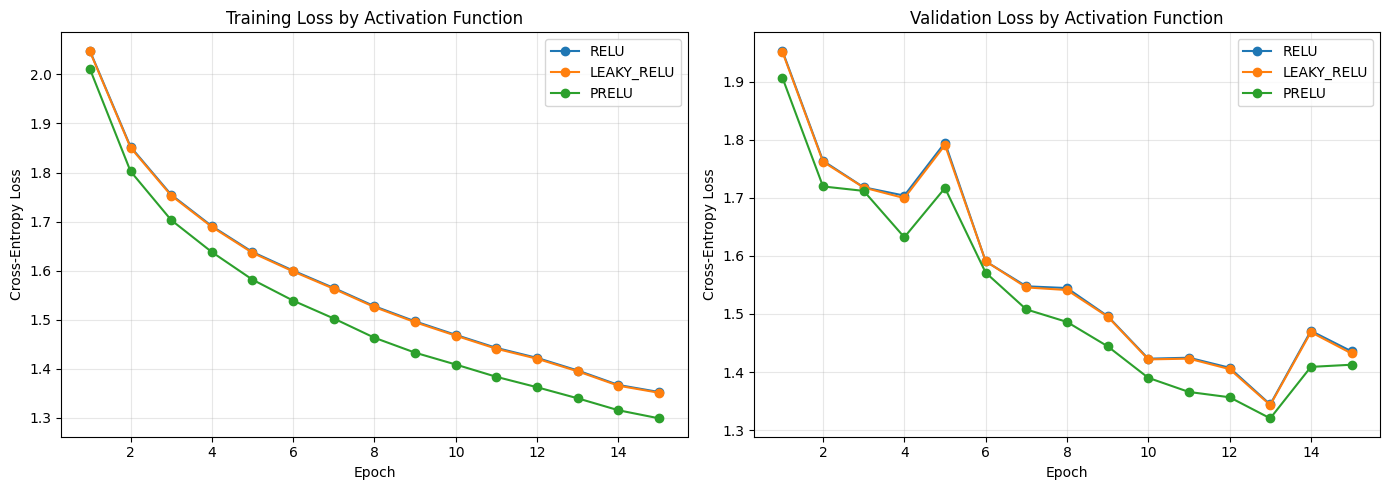

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for activation, result in activation_results.items():
  history = result["history"]
  epochs = range(1, len(history["train_loss"]) + 1)

  axes[0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label=activation.upper()
  )

  axes[1].plot(
    epochs,
    history["val_loss"],
    marker="o",
    label=activation.upper()
  )

axes[0].set_title("Training Loss by Activation Function")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation Loss by Activation Function")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Here for both graphs, there's several important trends.

In terms of training loss (left graph), all three activation functions showed a steady decrease in training loss, indicating that each model is successfully learning from the training data. However one thing to note is that ReLU and Leaky ReLU produce nearly identical curve, suggesting that Leaky ReLU's small negative slope has little impact on this particular CNN. Meanwhile PReLU consistently achieves lower training loss, finishing at around $1.30$, compared with $1.35$ for the other two functions. This suggests that its learnable negative slopes may improve the model's ability to fit the training data.

As for validation loss (right graph), it generally decreases for all three model, with fluctuation happening more often than in the training counterparts. PReLU achieves the lowest validation loss, while ReLU and Leaky ReLU remain nearly indistinguisable. 

Moving onto validation accuracy...

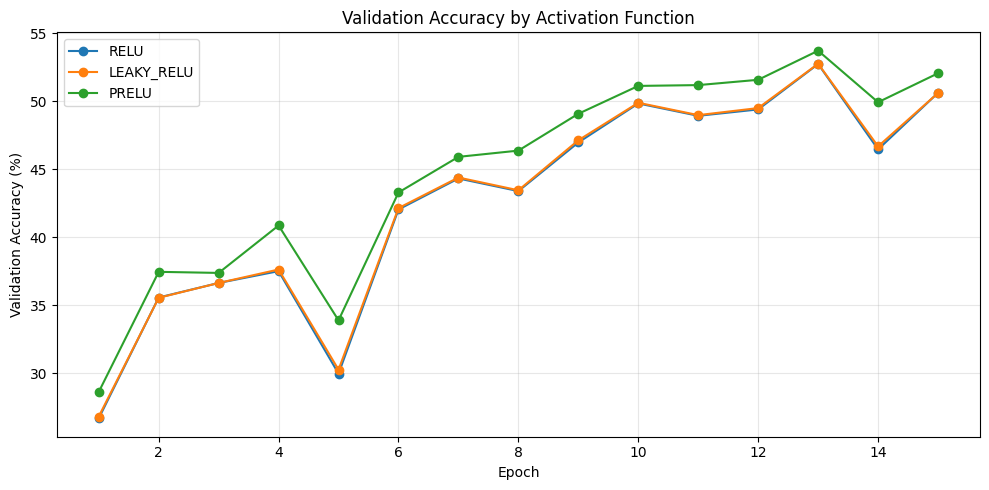

In [22]:
plt.figure(figsize=(10, 5))

for activation, result in activation_results.items():
  history = result["history"]
  epochs = range(1, len(history["val_accuracy"]) + 1)

  plt.plot(
    epochs,
    np.array(history["val_accuracy"]) * 100,
    marker="o",
    label=activation.upper()
  )

plt.title("Validation Accuracy by Activation Function")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Here, all three activation functions show an overall improvement in validation accuracy as training progresses, although some fluctuations occur between epochs. Again, ReLU and Leaky ReLU produce nearly identical results, while PReLU generally achieves higher validation accuracy.

Despite these differences, all three models experience occasional decreases in validation accuracy, indicating that improvements are not necessarily consistent across every epoch. Still, PReLU appears to perform slightly better, although additional experiments with different random seeds would be needed to determine whether this improvement is consistent.

To further compare the three activation functions, let's see how the three models classify individual images. Before doing so, I should make clear that I'm not looking at the accuracy of all three, rather I'm looking at the prediction behavior and confidence distributions when these models are given the images.

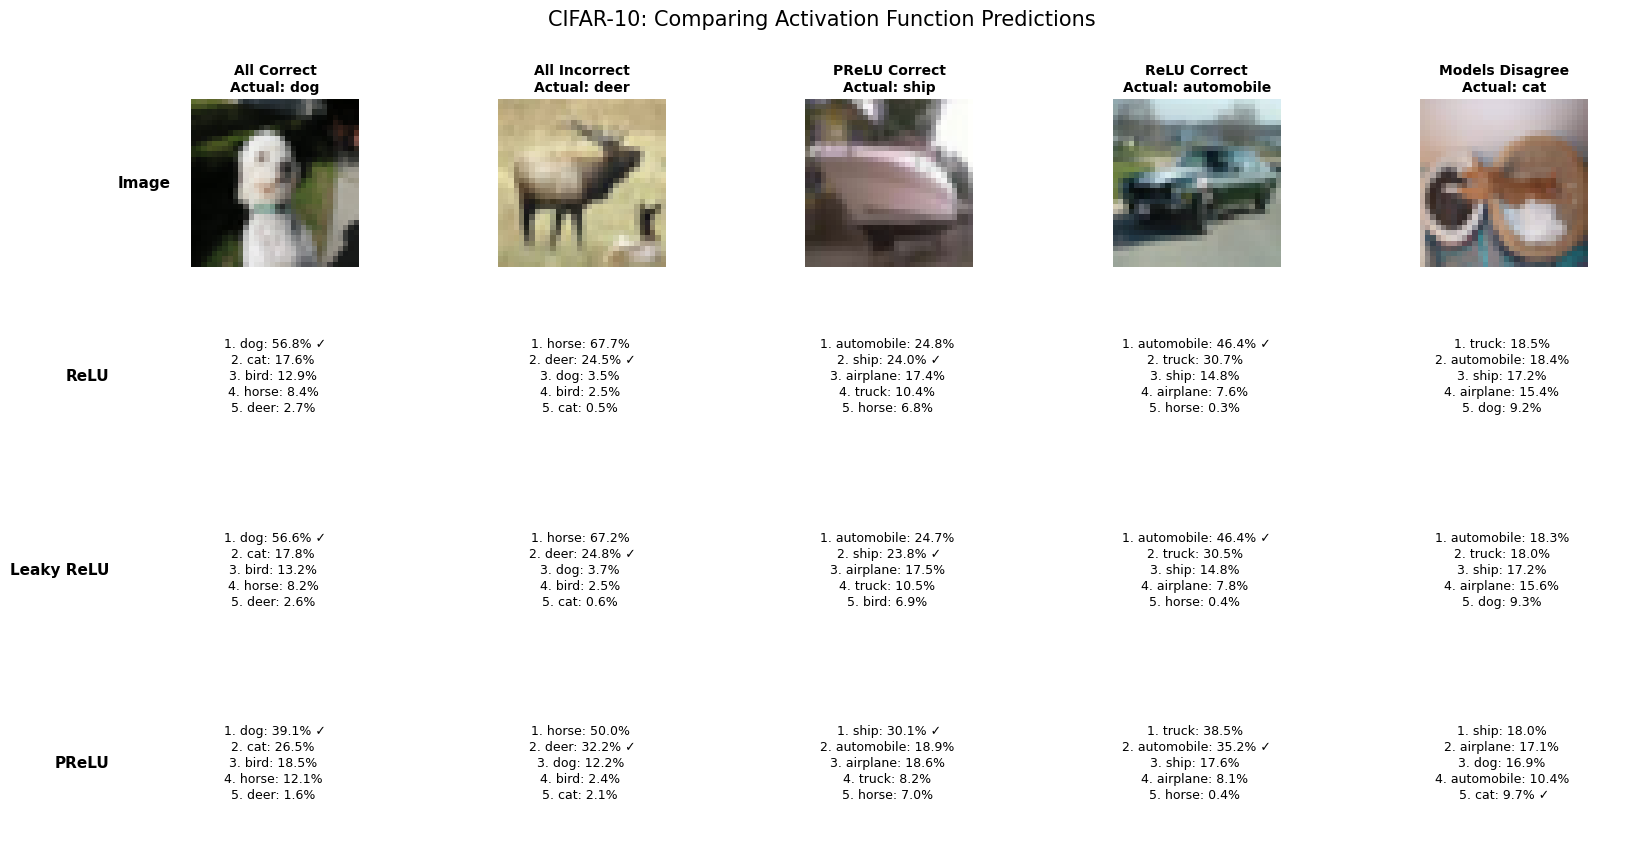

In [23]:
rng = np.random.default_rng(seed)

activation_names = ["relu", "leaky_relu", "prelu"]

# Collect predictions across the validation dataset
all_predictions = {}
all_confidences = {}

for activation in activation_names:
  model = activation_results[activation]["model"]
  model.eval()

  predictions_list = []
  confidences_list = []

  with torch.no_grad():
    for images, labels in val_loader:
      logits = model(images.to(device))
      probabilities = torch.softmax(logits, dim=1)

      confidence, predictions = probabilities.topk(5, dim=1)

      predictions_list.append(predictions.cpu())
      confidences_list.append(confidence.cpu())

  all_predictions[activation] = torch.cat(predictions_list)
  all_confidences[activation] = torch.cat(confidences_list)

# The validation loader is not shuffled, so these labels match its predictions
val_labels = np.array(full_train_dataset.targets)[val_dataset.indices]

relu_preds = all_predictions["relu"][:, 0].numpy()
leaky_preds = all_predictions["leaky_relu"][:, 0].numpy()
prelu_preds = all_predictions["prelu"][:, 0].numpy()

# Identify examples illustrating different model behaviors
categories = {
  "All Correct": np.flatnonzero(
    (relu_preds == val_labels) &
    (leaky_preds == val_labels) &
    (prelu_preds == val_labels)
  ),

  "All Incorrect": np.flatnonzero(
    (relu_preds != val_labels) &
    (leaky_preds != val_labels) &
    (prelu_preds != val_labels)
  ),

  "PReLU Correct": np.flatnonzero(
    (prelu_preds == val_labels) &
    (relu_preds != val_labels)
  ),

  "ReLU Correct": np.flatnonzero(
    (relu_preds == val_labels) &
    (prelu_preds != val_labels)
  ),

  "Models Disagree": np.flatnonzero(
    (relu_preds != leaky_preds) &
    (relu_preds != prelu_preds) &
    (leaky_preds != prelu_preds)
  )
}

# Select one distinct image from each category
selected_indices = []
selected_titles = []

for title, candidates in categories.items():
  available = np.setdiff1d(candidates, selected_indices)

  if len(available) == 0:
    print(f"No unused validation image found for: {title}")
    continue

  selected_idx = int(rng.choice(available))

  selected_indices.append(selected_idx)
  selected_titles.append(title)

# Reverse normalization for image display
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

# Horizontal figure: five columns, one per example
fig, axes = plt.subplots(
  4, len(selected_indices),
  figsize=(17, 9),
  squeeze=False
)

for col, (idx, title) in enumerate(zip(selected_indices, selected_titles)):
  image, actual_idx = val_dataset[idx]

  display_image = image * std + mean
  display_image = display_image.permute(1, 2, 0).clamp(0, 1).numpy()

  actual_class = class_names[actual_idx]

  # First row: original image
  axes[0, col].imshow(display_image)
  axes[0, col].set_title(
    f"{title}\nActual: {actual_class}",
    fontsize=10,
    fontweight="bold"
  )
  axes[0, col].axis("off")

  # Remaining rows: top-five predictions
  for row, activation in enumerate(activation_names, start=1):
    top_predictions = all_predictions[activation][idx]
    top_confidences = all_confidences[activation][idx]

    prediction_text = []

    for rank in range(5):
      predicted_idx = top_predictions[rank].item()
      confidence = top_confidences[rank].item()

      predicted_class = class_names[predicted_idx]
      marker = "✓" if predicted_idx == actual_idx else ""

      prediction_text.append(
        f"{rank + 1}. {predicted_class}: {confidence:.1%} {marker}"
      )

    axes[row, col].text(
      0.5, 0.5,
      "\n".join(prediction_text),
      ha="center",
      va="center",
      fontsize=9,
      linespacing=1.3,
      transform=axes[row, col].transAxes
    )

    axes[row, col].axis("off")

# Row labels
row_labels = ["Image", "ReLU", "Leaky ReLU", "PReLU"]

for row, label in enumerate(row_labels):
  axes[row, 0].text(
    -0.12, 0.5,
    label,
    transform=axes[row, 0].transAxes,
    ha="right",
    va="center",
    fontsize=11,
    fontweight="bold"
  )

plt.suptitle(
  "CIFAR-10: Comparing Activation Function Predictions",
  fontsize=15
)

plt.subplots_adjust(
  left=0.10,
  right=0.98,
  top=0.88,
  bottom=0.05,
  wspace=0.15,
  hspace=0.15
)

plt.show()

Looking at the model's actual predictions, the first main standout is that once again both ReLU and Leaky ReLU are behaving almost identically, with both models producing roughly the same ranking of predicted classes, with only minor differences in the scores. This continues the trend in the previous graphs, in that introducing a small negative slope doesn't appear to substantially change the CNN's predictions.

Meanwhile when comparing PReLU's prediction behavior to the other two functions, it produces more noticeable differences in its prediction classes and confidence scores. In some cases, PReLU correctly identifies images that the other models misclassify, while in other cases, the opposite occurs. This suggests that PReLU's learnable negative slopes can influence how the CNN distinguishes between different image classes, although these changes don't necessarily improve individual predictions.

And finally, looking at the five highest-scoring classes gives additional insight into the models' classifcation behavior. Even when a model incorrectly classifies an image, the correct class amy still appear among the alternative guesses. This suggests that the model assigns some confidence to the correct category but ranks another class higher. Comparing these ranking across activation functions helps illustrate how the models distribute their confidence among different classes, even when their final predictions are similar.

Overall, the results suggest that PReLU generally provides a modest improvement in training and validation performance compared to ReLU and Leaky ReLU; while ReLU and Leaky ReLU exhibit nearly identical behavior, indicating that introducing a small fixed negative slope has a limited influence on this CNN. These findings suggest that learnable activation parameters can affect how a neural network trains and classifies images, even when the architecture and other training settings remain unchanged.

#### Experiment 2: Comparing Initialization Methods
Now let's move onto investigating another important component of neural network training: **weight initialization**. 

This experiment will compare **Xavier and He Initialization** in terms of its performance and training behavior while keeping regular ReLU as the activation function and the underlying architecture the same.

Before doing that however, let's compare how each method affects the propagation of activations through an untrained CNN. Since weight initialization determines the initial distribution of a network's parameters, it can influence whether signals shrink or grow as they pass through successive layers.

To investigate this, I'll measure the variance of the outputs from each convolutional layer using the same batch of CIFAR-10 images. Both models will use ReLU activations and identical architecutres with only weight initialization being the only variable changed.

In [24]:
def measure_activation_variance(model, images):
  variances = []
  hooks = []

  def capture_variance(module, inputs, output):
    variances.append(output.detach().float().var(unbiased=False).item())

  for module in model.modules():
    if isinstance(module, nn.Conv2d):
      hooks.append(module.register_forward_hook(capture_variance))

  model.eval()

  with torch.no_grad():
    model(images)

  for hook in hooks:
    hook.remove()

  return variances


# Use the same validation batch for both models
images, _ = next(iter(val_loader))
images = images.to(device)

initialization_variances = {}

for method in ["xavier", "he"]:
  model = create_model(
    activation="relu",
    initialization=method,
    seed=seed
  ).to(device)

  initialization_variances[method] = measure_activation_variance(
    model,
    images
  )

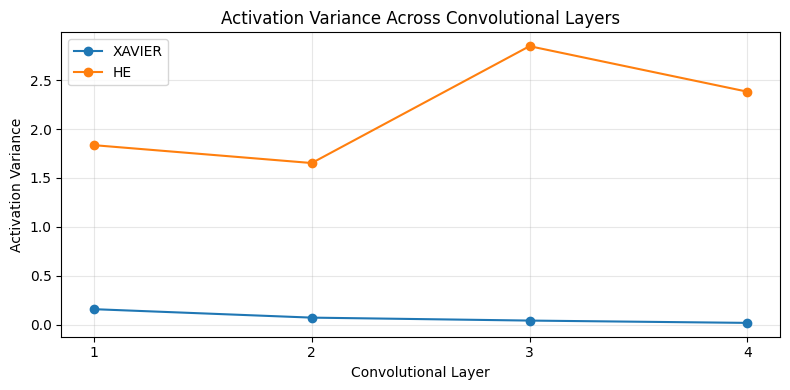

In [25]:
plt.figure(figsize=(8, 4))

for method, variances in initialization_variances.items():
  layers = range(1, len(variances) + 1)

  plt.plot(
    layers,
    variances,
    marker="o",
    label=method.upper()
  )

plt.title("Activation Variance Across Convolutional Layers")
plt.xlabel("Convolutional Layer")
plt.ylabel("Activation Variance")
plt.xticks(range(1, 5))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Here, the graph reveals a clear difference in how Xavier and He initialization affect the signals passing through the untrained CNN. Xavier initialization exhibits a tendency for activation variance to decrease as signals propagate deeper into the network, suggesting that the intermediate signals become less variable. In contrast, He initialization maintains larger activation variances, although fluctuations between layers are still present. These observations are consistent with He initialization's design for ReLU-based networks, where its weight variance accounts for the effect of the activation function. Overall, the comparison illustrates how weight initialization can influence signal propagation before training begins.

Moving onto the actual performance of the initialization methods.

In [26]:
initialization_results = {
  "he": activation_results["relu"]
}

print("Training ReLU model with Xavier initialization")

model, history = run_experiment(
  activation="relu",
  initialization="xavier",
  epochs=15,
  learning_rate=0.01,
  seed=seed
)

initialization_results["xavier"] = {
  "model": model,
  "history": history
}

Training ReLU model with Xavier initialization
Epoch 1/15 | Train Loss: 2.2453 | Val Loss: 2.1726 | Val Accuracy: 20.23% | Time: 7.9s
Epoch 2/15 | Train Loss: 2.1007 | Val Loss: 2.0518 | Val Accuracy: 25.31% | Time: 8.0s
Epoch 3/15 | Train Loss: 2.0128 | Val Loss: 1.9797 | Val Accuracy: 27.49% | Time: 7.9s
Epoch 4/15 | Train Loss: 1.9295 | Val Loss: 1.8931 | Val Accuracy: 31.03% | Time: 7.9s
Epoch 5/15 | Train Loss: 1.8503 | Val Loss: 1.9024 | Val Accuracy: 25.20% | Time: 8.1s
Epoch 6/15 | Train Loss: 1.7898 | Val Loss: 1.7613 | Val Accuracy: 34.07% | Time: 8.0s
Epoch 7/15 | Train Loss: 1.7402 | Val Loss: 1.7128 | Val Accuracy: 37.18% | Time: 7.8s
Epoch 8/15 | Train Loss: 1.7003 | Val Loss: 1.6953 | Val Accuracy: 36.67% | Time: 7.9s
Epoch 9/15 | Train Loss: 1.6702 | Val Loss: 1.6499 | Val Accuracy: 39.47% | Time: 8.2s
Epoch 10/15 | Train Loss: 1.6457 | Val Loss: 1.6337 | Val Accuracy: 40.58% | Time: 8.0s
Epoch 11/15 | Train Loss: 1.6212 | Val Loss: 1.6364 | Val Accuracy: 41.18% | Time:

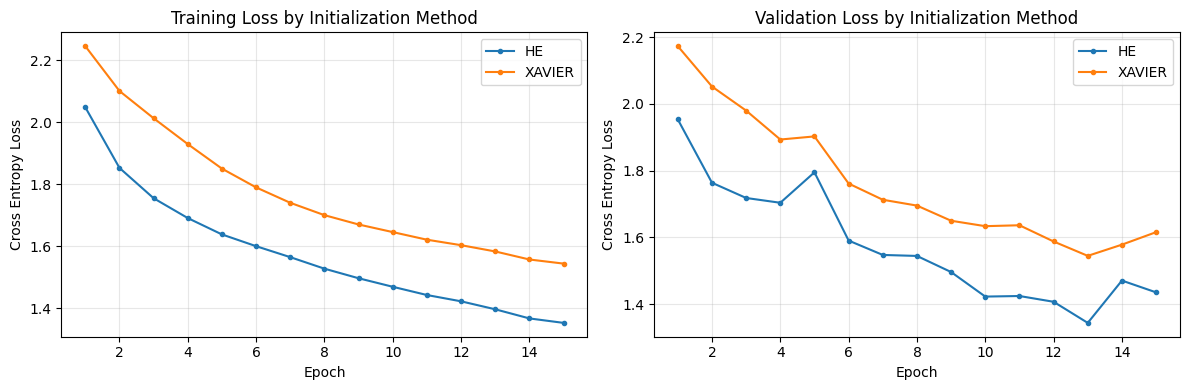

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for method, result in initialization_results.items():
  history = result["history"]
  epochs = range(1, len(history["train_loss"]) + 1)

  axes[0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    markersize=3,
    label=method.upper()
  )

  axes[1].plot(
    epochs,
    history["val_loss"],
    marker="o",
    markersize=3,
    label=method.upper()
  )

axes[0].set_title("Training Loss by Initialization Method")
axes[1].set_title("Validation Loss by Initialization Method")

for ax in axes:
  ax.set_xlabel("Epoch")
  ax.set_ylabel("Cross Entropy Loss")
  ax.legend()
  ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Here, both initialization methods demonstrate a consistent decrease in training loss, indicating that the models are successfully learning from the training data. However, He initialization maintains a lower training loss throughout the experiment, suggesting that it allows the CNN to learn more efficiently under the chosen training settings. Xavier initialization also demnstrates steady improvement, but its loss decreases more gradually.

As for the validation loss, a similar pattern can be observed in the curves, with fluctuation occuring between epochs. He initialization tends to achieve lower validation loss than Xavier initialization, suggesting that its advantage extends beyond fitting the training data. These results are consistent with the earlier activation variance experiment, where He initialization maintains stronger signal propagation through the convolutional layers.

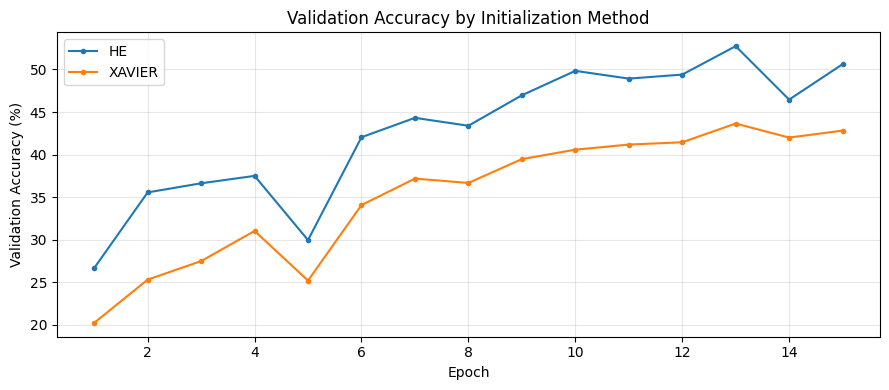

In [28]:
plt.figure(figsize=(9, 4))

for method, result in initialization_results.items():
  history = result["history"]
  epochs = range(1, len(history["val_accuracy"]) + 1)

  plt.plot(
    epochs,
    [accuracy * 100 for accuracy in history["val_accuracy"]],
    marker="o",
    markersize=3,
    label=method.upper()
  )

plt.title("Validation Accuracy by Initialization Method")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

And finally in terms of validation accuracy, both methods demonstrate an overall improvement in validation accuracy as training progresses, meaning that the CNN can successfully learn using either method. However He initialization consistently achieves higher validation accuracy than Xavier initialization, suggesting that it provides a more favorable starting point for training an ReLU-based CNN.

Overall, between the activation variance, loss, and accuracy comparisons, they collectively suggest that He initialization is better suited to ReLU-based CNNs under the tested conditions. Whilst Xavier initialization still allows the network to learn, He initialization appears to support more effective signal propagation and faster improvements in model performance.

#### Conclusions, Limitations, and Final Thoughts
In this report, I investigated how activation functions and weight initialization influences the training and performance of a convolutional neural network (CNN) on a CIFAR-10 dataset.

In terms of activation functions, I found that ReLU and Leaky ReLU exhibited nearly identical behavior in terms of training loss, validation loss, and classificiation accuracy. Meanwhile PReLU generally demonstrated a modest improvement in performance, suggesting that its learnable negative slopes can provide additional flexibility during training. Examining individual predictions also revealed differences in how the models ranked classes and distributed their confidence scores.

In terms of weight initialization methods, I found that initializing weights using the He initialization method for an ReLU-based CNN is much better suited compared to the Xavier initialization in many ways. For starters, the activation variance of Xaiver's exhibits decreased pre-activation variance across successive convolutional layers, while He initialization maintains larger variances. During training, He initialization generally achieved lower loss and higher validation accuracy, supporting its mathematical motivation for use with ReLU-based networks.

For each of these experiments, a few limitations should be acknowledged.
- The CNN used in the experiments itself uses a relatively simply architecture and a fixed training duration. If more advanced architectures or longer training were permitted, then results could've differed.
- Each configuration was evaluated using a single random seed, reperating the experiment with multiple seeds would help determine whether the observed differences are consistent.
- For the hyperparameters, the learning rate, batch size and optimizer were fixed to isolate the variables being investigated. Exploring different hyperparameters could've revealed how these methods behave under other training conditions

Overall, these experiments demonstrate that the mathematical choices made when constructing a neural network can meaningfully influence its learning behavior and performance. While the activation-function comparison revealed relatively modest differences, the initialization experiment demonstrated a more noticeable effect on training dynamics and validation performance.

And as a personal note, being able to use these experiments as a way to investigate CNNs hands on allows me to better understand what CNNs are themselves, and how they could identify an object based on a given image, which for me demystified somewhat the concept of CNNs overall.

For reference, this part of the report is based on this 2015 paper called [Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification](https://arxiv.org/abs/1502.01852) written by He, Kaiming, et. al.